# El umbral: R0, el umbral de rebaño y la inmunización en los casos calculados

- **Nivel:** 1, Fundamentos
- **Prerrequisitos:** cuadernos 01 y 02 del tema 01-getting-started
- **Tiempo de lectura:** unos 15 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular $R_0$ y el umbral de rebaño $1 - 1/R_0$ para cada caso calculado;
- explicar por qué un caso con $R_0 \le 1$ no tiene umbral que cruzar;
- correr el motor con parte de la población inmunizada y ver que el brote se apaga sobre el umbral.

## Preparación

El entorno de los cuadernos está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este cuaderno, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica un paquete propio: su método vive en `data-pipeline/pipeline/`, así que el cuaderno importa ese código por su ruta. Un producto importa en cambio su propio paquete de PyPI (`pip install <paquete>==<versión>`).

La siguiente celda importa las herramientas e imprime sus versiones.

In [1]:
# Imprimir las versiones de las herramientas de este cuaderno, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


El motor se importa desde `data-pipeline/` por su ruta, como en el tema 01.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; los módulos del pipeline se importan por su ruta
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Datos

Los parámetros de los cinco casos calculados.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce desde los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay conjunto de datos de terceros, así que no aplica licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<case>.json`.

La siguiente celda define los lectores y lista los casos.

In [3]:
# Dos lectores de los artefactos versionados: un archivo ausente detiene el cuaderno y nombra su ruta
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("casos que pueden despegar:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
casos que pueden despegar: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


## Método

$R_0 = \beta / \gamma$ es el cociente reproductivo básico (Diekmann, Heesterbeek y Metz, 1990). Cuando una fracción $v$ de la población es inmune al inicio, una persona infectada encuentra susceptibles solo una fracción $1 - v$ del tiempo, así que el cociente efectivo es $R_0 (1 - v)$. El brote no puede crecer cuando esto es menor que 1, es decir cuando

$$v > 1 - \frac{1}{R_0}$$

Este es el umbral de rebaño de Diekmann, Heesterbeek y Metz (1990). Para $R_0 \le 1$ el lado derecho no es positivo: no hay nada que inmunizar. La siguiente celda calcula el cociente y el umbral para cada caso.

In [4]:
# R0 y el umbral de rebaño de cada caso calculado
for case_id in CASES:
    p = params_of(case_id)
    r0 = p.beta / p.gamma
    threshold = f"{1 - 1 / r0:.3f}" if r0 > 1 else "ninguno (R0 <= 1)"
    print(f"{case_id:18s} R0={r0:5.2f}  umbral de rebaño: {threshold}")

CTRL_degenerate    R0= 2.00  umbral de rebaño: 0.500
EX01_subcritical   R0= 0.72  umbral de rebaño: ninguno (R0 <= 1)
EX02_epidemic      R0= 2.75  umbral de rebaño: 0.636
EX03_fast_burn     R0= 6.00  umbral de rebaño: 0.833
EX04_slow_spread   R0= 1.20  umbral de rebaño: 0.167


Para probar el umbral con el motor, se inmuniza una fracción $v$ de la población al inicio. El motor no tiene parámetro de inmunidad, así que la celda usa una equivalencia exacta: una población $N(1-v)$ con tasa de contacto $\beta(1-v)$ tiene la misma tasa de nuevas infecciones, $\beta (1-v) S I / (N (1-v)) = \beta S I / N$, y los mismos susceptibles al inicio, que la población completa con una fracción $v$ inmune. La tasa de ataque se divide luego sobre la población completa. La celda corre el caso de epidemia con 0%, 30%, 60% y 70% de inmunizados; su umbral es el que se imprimió arriba.

v=0.0  R0_eff=2.75  pico de infectados=  27345.2  infectados en total=0.9237
v=0.3  R0_eff=1.92  pico de infectados=   9957.7  infectados en total=0.5446
v=0.6  R0_eff=1.10  pico de infectados=    216.4  infectados en total=0.0496
v=0.7  R0_eff=0.83  pico de infectados=     50.0  infectados en total=0.0028


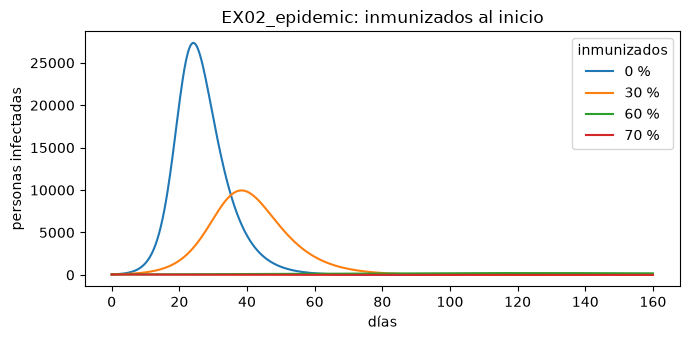

In [5]:
# Correr el caso de epidemia con una fracción v inmune al inicio, mediante los parámetros equivalentes
p = params_of("EX02_epidemic")
coverages = [0.0, 0.3, 0.6, 0.7]
runs = {}
for v in coverages:
    scaled = SIRParams(p.case_id, p.beta * (1 - v), p.gamma, p.N * (1 - v), p.I0, p.days)
    runs[v] = simulate(scaled)
    share = runs[v].R[-1] / p.N
    print(f"v={v:.1f}  R0_eff={p.beta / p.gamma * (1 - v):.2f}  pico de infectados={runs[v].peak_I:9.1f}  infectados en total={share:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for v, r in runs.items():
    ax.plot(r.t, r.I, label=f"{int(v * 100)} %")
ax.set_xlabel("días")
ax.set_ylabel("personas infectadas")
ax.set_title("EX02_epidemic: inmunizados al inicio")
ax.legend(title="inmunizados")
fig.tight_layout()
plt.show()

## Resultados

La primera tabla lista R0 y el umbral de rebaño por caso: el caso de epidemia necesita cerca de 64% de la población inmune, el de combustión rápida cerca de 83%, el de propagación lenta solo cerca de 17%, y el caso subcrítico y el control no tienen umbral que cruzar. La segunda tabla y la figura corren el caso de epidemia: con 0% y 30% de inmunizados el brote ocurre igual, con un pico más bajo y más tardío; con 60%, justo bajo el umbral, el cociente efectivo queda apenas sobre 1 y el brote es pequeño y lento; con 70%, sobre el umbral, el cociente efectivo queda bajo 1, los infectados nunca superan a los iniciales y la epidemia se apaga. Lo que estas corridas no muestran es el tamaño exacto del brote cerca del umbral: el siguiente cuaderno resuelve el tamaño final.

## Resumen

- $R_0 = \beta / \gamma$ decide el crecimiento; el umbral de rebaño es $1 - 1/R_0$ cuando $R_0 > 1$.
- Una fracción inmune sobre el umbral mantiene el cociente efectivo bajo 1 y el brote se apaga.
- Siguiente: el cuaderno 02 de este tema resuelve el tamaño final y lo compara con el curso simulado.

## Referencias

- Diekmann, O., Heesterbeek, J. A. P. and Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. and Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- El motor y los casos de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

Lo que se atribuye a cada obra es lo que registra la base de investigación del SDD (`docs/design/SDD.md`); el texto de sus páginas no se volvió a leer, solo sus registros de Crossref.